# Hyperparameter Tuning with Grid Search

This tutorial tunes a random-forest classifier with `GridSearchCV`. It uses the built-in breast-cancer dataset, stratified cross-validation on training rows, average precision for model selection, and one final holdout evaluation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

RANDOM_SEED = 16
OUTPUT_DIR = Path('generated/tuning-016')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

dataset = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    dataset.data,
    dataset.target,
    test_size=0.25,
    stratify=dataset.target,
    random_state=RANDOM_SEED,
)
print(f'train rows: {len(X_train)}; holdout rows: {len(X_test)}')

train rows: 426; holdout rows: 143


## 1. Define the Parameter Grid

Every combination in the compact grid is evaluated with stratified cross-validation. Average precision is used because it evaluates the probability ranking of the positive class.

In [2]:
parameter_grid = {
    'n_estimators': [100, 180],
    'max_depth': [None, 6],
    'min_samples_leaf': [1, 3],
    'max_features': ['sqrt', 0.7],
}
cross_validation = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED)
search = GridSearchCV(
    RandomForestClassifier(
        class_weight='balanced', random_state=RANDOM_SEED, n_jobs=-1
    ),
    param_grid=parameter_grid,
    scoring='average_precision',
    cv=cross_validation,
    n_jobs=1,
    return_train_score=True,
)
search.fit(X_train, y_train)
print('best parameters:', search.best_params_)
print(f'best cross-validation average precision: {search.best_score_:.3f}')

best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 180}
best cross-validation average precision: 0.994


## 2. Compare with a Baseline

The tuned model and a prevalence-based dummy classifier are scored on the same untouched holdout. The classification report is descriptive and should be interpreted with the probability metrics and confusion matrix.

In [3]:
probabilities = search.best_estimator_.predict_proba(X_test)[:, 1]
predictions = search.best_estimator_.predict(X_test)
baseline = DummyClassifier(strategy='prior').fit(X_train, y_train)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]
metrics = pd.DataFrame(
    {
        'average_precision': [
            average_precision_score(y_test, probabilities),
            average_precision_score(y_test, baseline_probabilities),
        ],
        'roc_auc': [
            roc_auc_score(y_test, probabilities),
            roc_auc_score(y_test, baseline_probabilities),
        ],
    },
    index=['Tuned random forest', 'Prevalence baseline'],
)
print(metrics.round(3).to_string())
print(classification_report(y_test, predictions, target_names=dataset.target_names))
assert metrics.loc['Tuned random forest', 'average_precision'] > metrics.loc['Prevalence baseline', 'average_precision']

                     average_precision  roc_auc
Tuned random forest              0.996    0.993
Prevalence baseline              0.629    0.500
              precision    recall  f1-score   support

   malignant       0.98      0.94      0.96        53
      benign       0.97      0.99      0.98        90

    accuracy                           0.97       143
   macro avg       0.97      0.97      0.97       143
weighted avg       0.97      0.97      0.97       143



## 3. Inspect the Search and Holdout Errors

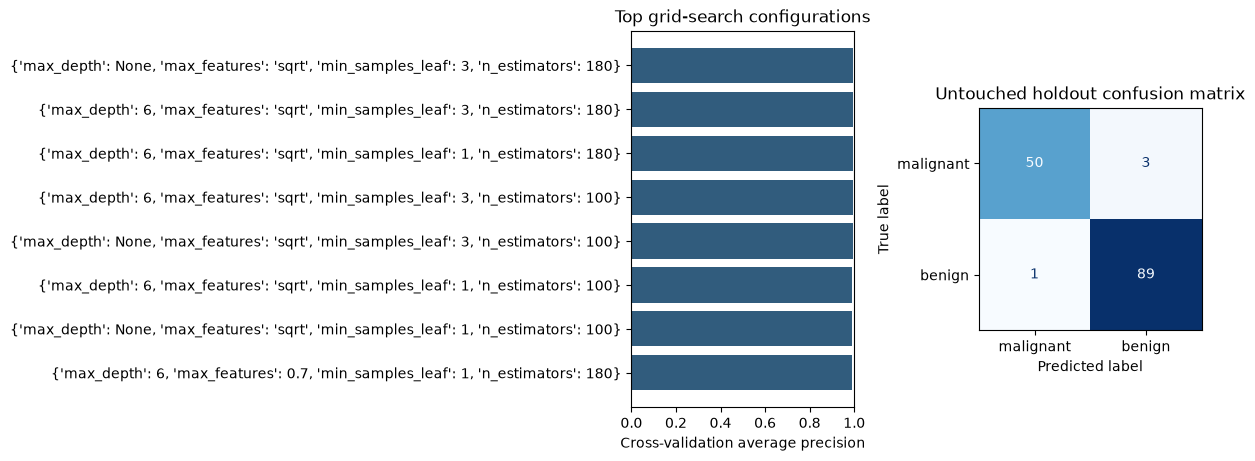

saved: generated\tuning-016\grid-search-classification.png


In [4]:
search_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(8)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].barh(
    search_results['params'].astype(str),
    search_results['mean_test_score'],
    color='#315c7d',
)
axes[0].invert_yaxis()
axes[0].set(title='Top grid-search configurations', xlabel='Cross-validation average precision', xlim=(0, 1))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=dataset.target_names,
    colorbar=False,
    cmap='Blues',
    ax=axes[1],
)
axes[1].set_title('Untouched holdout confusion matrix')
figure_path = OUTPUT_DIR / 'grid-search-classification.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
print(f'saved: {figure_path}')